In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

In [11]:
MU_B  = 1# eV/T
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [12]:
# Band filling values
n_min = 0.1
n_max = 0.99
n_count = 20

# Magnetic field values
Ha_min = -3
Ha_max = -2
Ha_count = 2

# kBT values
kBT_min = -2
kBT_max = 2
kBT_count = 5 

# U = 10
# U = 1
U = 0


distros = [DistType.NFL, DistType.SSL, DistType.FD, DistType.HUBBARD]#DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
# n  = np.array([ 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# kBT = np.array([0.1, 1.0], dtype=np.float64)  # NB
kBT = np.logspace(kBT_min, kBT_max, kBT_count, dtype=np.float64)  # NB
H_a = np.array([0.0], dtype=np.float64) # NH
# H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
# H_a = np.concat([np.array([0.8]), H_a])

In [13]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

In [14]:
mu = Path("chemical_potential_results00.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    kBT = k_BT
    H_a = np.unique(mu_df["H_a"])
    mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

else:
    mu_df = chemical_potential(
        distros=distros,
        n_vals=n,
        kBT_vals=kBT,
        H_a_vals=H_a,
        N=N,
        E=e_k,
        U=U,
        solver_opts=native_opts,
        x0=-1.0,
        a0=-5.0,
        b0=5.0,
    )
    mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged      residual
distro  n        k_BT   H_a                                                
NFL     0.100000 0.01   0.0  -2.838719          23       True  1.020918e-07
        0.146842 0.01   0.0  -2.359644          21       True  2.129520e-08
        0.193684 0.01   0.0  -1.919185          23       True  8.221387e-08
        0.240526 0.01   0.0  -1.513393          20       True  4.542295e-08
        0.287368 0.01   0.0  -1.148342          13       True  2.344047e-08
...                                ...         ...        ...           ...
HUBBARD 0.802632 100.00 0.0 -40.002502          23       True  4.308847e-08
        0.849474 100.00 0.0 -30.338797          23       True  2.075396e-08
        0.896316 100.00 0.0 -20.813702          23       True  3.449852e-08
        0.943158 100.00 0.0 -11.381824          23       True  5.081148e-09
        0.990000 100.00 0.0  -2.000266          24       True  1.735230e-09

[400 rows x 4 columns]

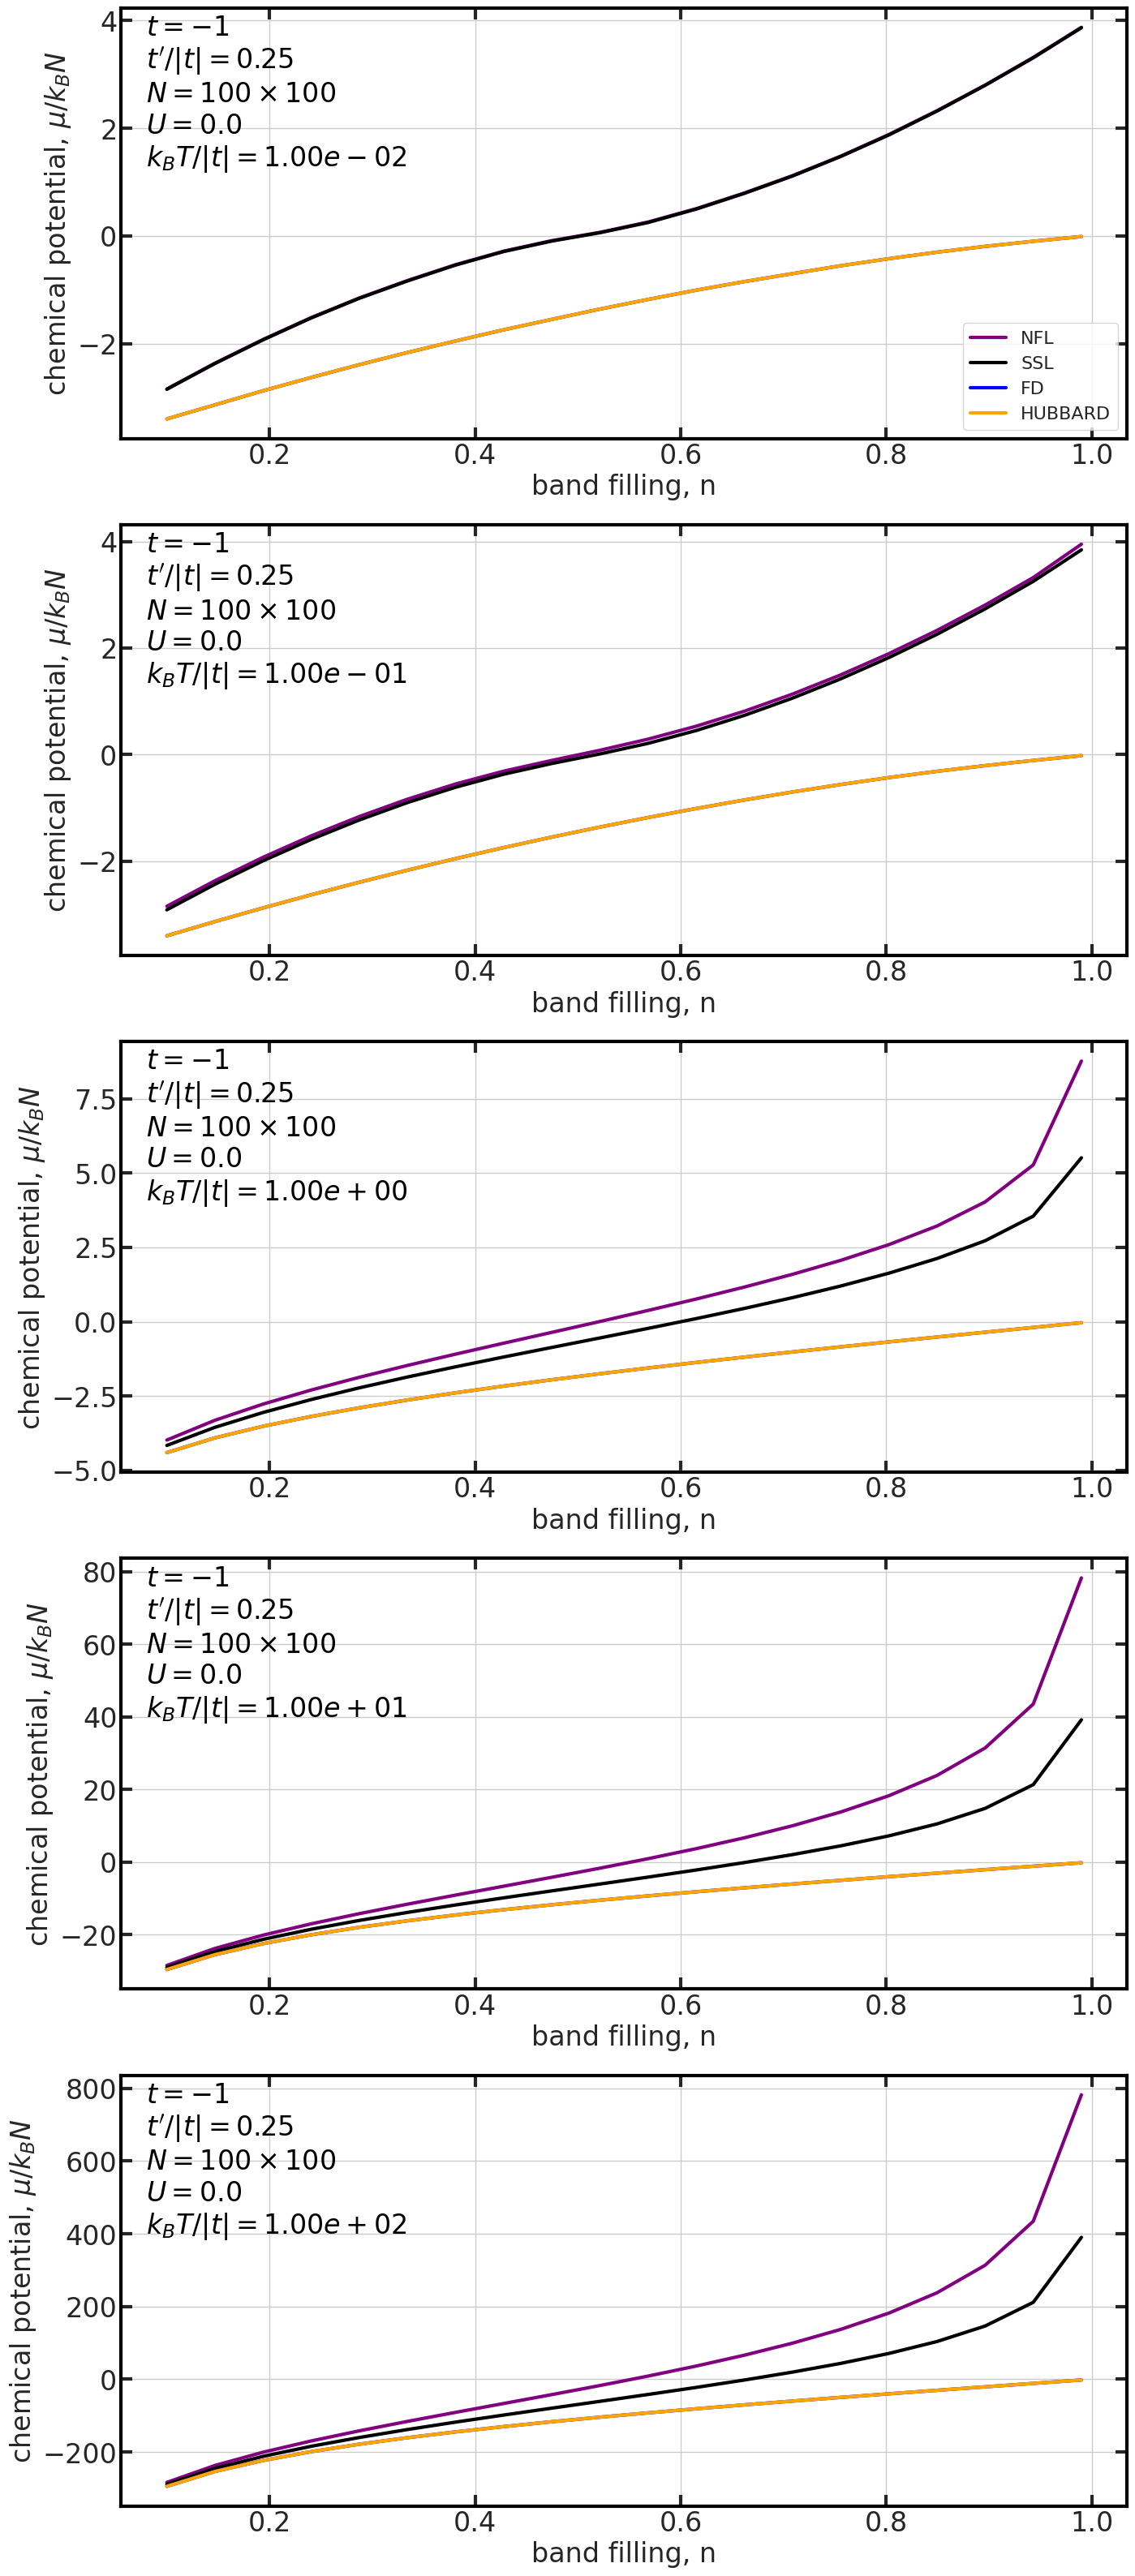

In [15]:
# Select a magnetic field to plot
H_a_plot = H_a[0]
kBT_plot = kBT

# Plot
plotter.plot_scalar_result(
    results=mu_df,
    x_param="n",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=[d.name for d in distros],
    subplots_param="kBT",
    subplots_vals=kBT_plot,
    cols=1,
    figsize=(16, 8)
)
plt.show()

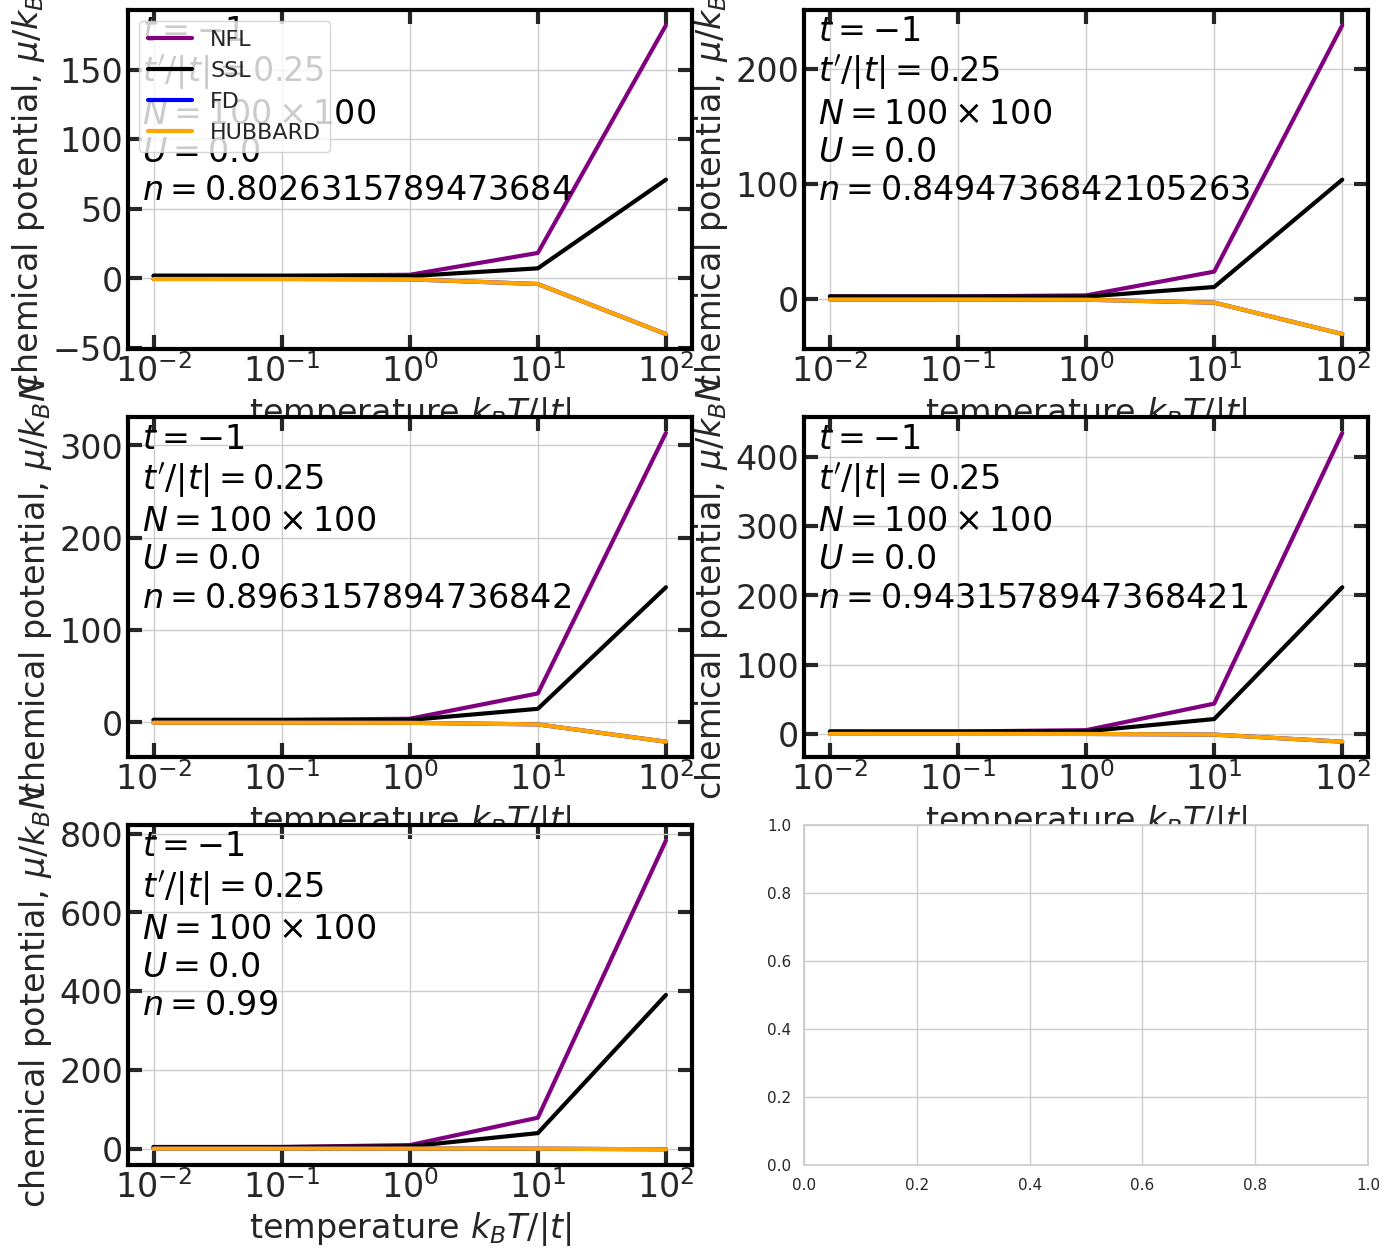

In [16]:
n_plot = n[-5:]
H_a_plot = H_a[0]

# Plot
plotter.plot_scalar_result(
    results=mu_df,
    x_param="k_BT",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

/home/mateuszzx/Workspace/Programming_Workspace/Spalek_Workspace/quantum-statistics-solver/tools/scientific_plot_v2.py:95: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale(xscale)


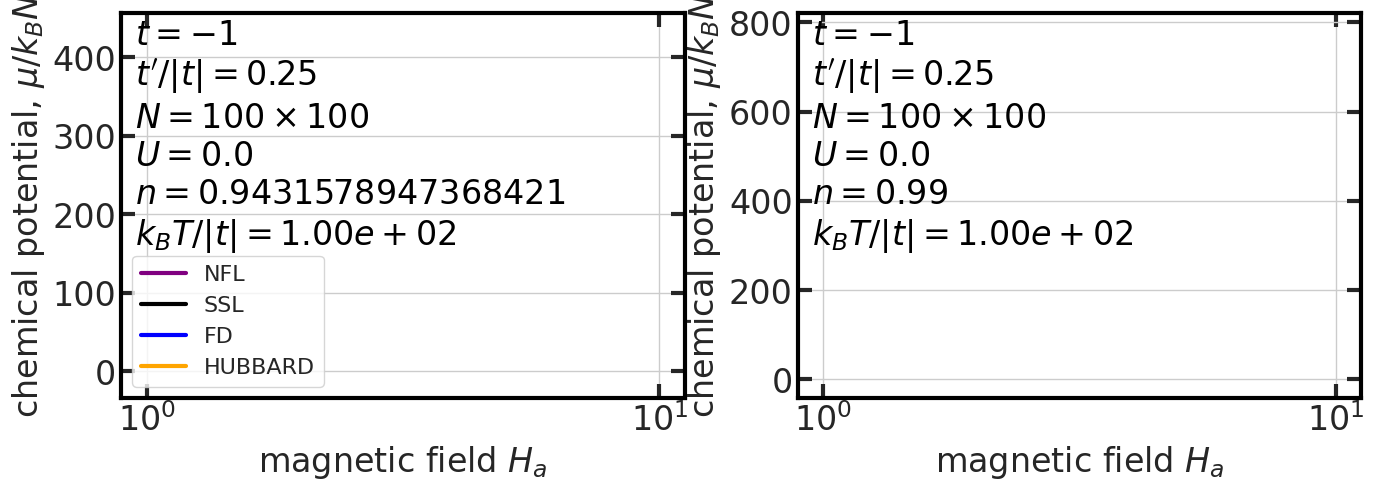

In [17]:
n_plot = n[-2:]
kBT_plot = kBT[0]
plotter.plot_scalar_result(
    results=mu_df,
    x_param="H_a",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"kBT": kBT[-1]},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

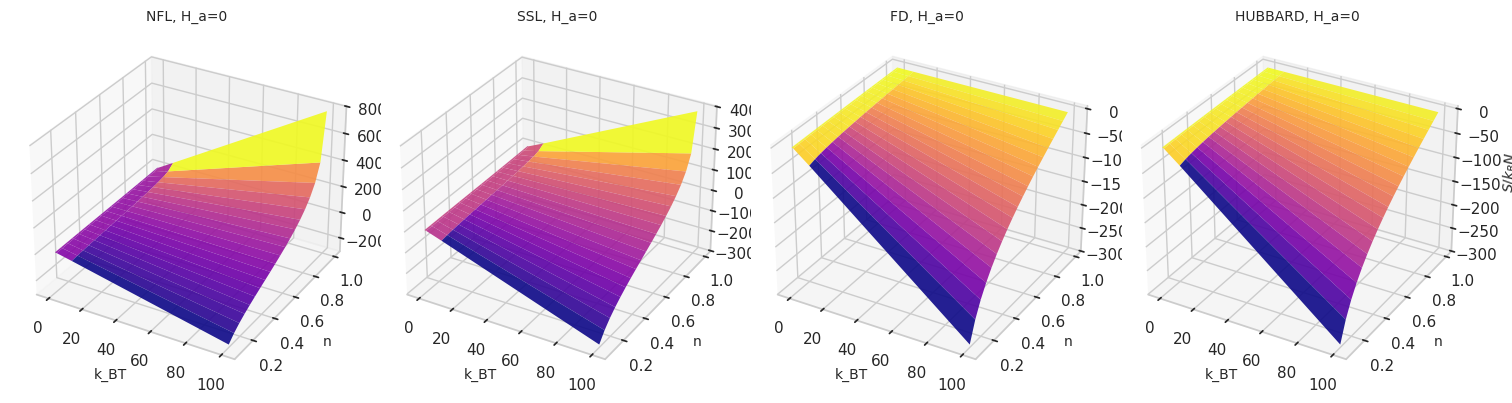

In [18]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
n_rows = [n[0], n[len(n)//2]] 
plotter.plot_3d_results(
    results=mu_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a[:2],     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="mu",          # or "entropy" if you have calculated it
    distros=[d.name for d in distros],
    # figsize=(15, 10)
)
plt.show()